<a href="https://colab.research.google.com/github/ErickRC13/Investigaci-n-de-Operaciones-/blob/main/cadenas_absorbentes.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# <font color="skyblue"> Cadenas absorbentes — Simulación

**Alumno:** Erick Ramirez Cruz  
**Materia:** Investigación de Operaciones  
**Profesor:** Ricardo Medel Esquivel  

### Ejercicios de la Tarea 5


## Objetivo

En este cuaderno se resuelven **por simulación** los dos ejercicios de la Tarea 5.

La idea es repetir cada experimento muchas veces y comparar el resultado obtenido por simulación con el resultado calculado de forma analítica.


### <font color="slategray"> Librerías

Se utilizará `random` para generar los movimientos aleatorios y `matplotlib` únicamente para mostrar gráficamente los resultados.


In [25]:
import random
import matplotlib.pyplot as plt


# Semilla para poder reproducir los mismos resultados
random.seed(2026)



# <font color="royalblue">1) Rata en el laberinto</font>

Los estados **7** y **8** son absorbentes:

- Estado 7: comida.
- Estado 8: descarga eléctrica.

Los estados 0, 1, 2, 3, 4, 5 y 6 son transitorios.

Si un compartimento tiene \(k\) salidas, cada salida se elige con probabilidad $\frac{1}{k}$.



### Paso 1. Definir las salidas de cada compartimento

A partir del dibujo del laberinto, las conexiones son:

$$
0 \to \{1,2\}, \quad
1 \to \{0,3,7\}, \quad
2 \to \{0,3,8\}
$$

$$
3 \to \{1,2,4,5\}, \quad
4 \to \{3,6,7\}, \quad
5 \to \{3,6,8\}, \quad
6 \to \{4,5\}
$$

Los estados **7** y **8** permanecen en sí mismos.


In [26]:
salidas = {
    0: [1, 2],
    1: [0, 3, 7],
    2: [0, 3, 8],
    3: [1, 2, 4, 5],
    4: [3, 6, 7],
    5: [3, 6, 8],
    6: [4, 5],
    7: [7],
    8: [8]
}

for estado in salidas:
    print(estado, "->", salidas[estado])


0 -> [1, 2]
1 -> [0, 3, 7]
2 -> [0, 3, 8]
3 -> [1, 2, 4, 5]
4 -> [3, 6, 7]
5 -> [3, 6, 8]
6 -> [4, 5]
7 -> [7]
8 -> [8]


### Paso 2. Simular el recorrido de una rata

La función inicia en un compartimento y continúa hasta llegar a 7 u 8.

`random.choice()` elige una de las salidas disponibles con la misma probabilidad, por lo que representa la condición $\frac{1}{k}$ del problema.


In [27]:
def simular_rata(inicio=0):
    estado = inicio
    ruta = [estado]

    while estado not in [7, 8]:
        estado = random.choice(salidas[estado])
        ruta.append(estado)

    return estado, ruta


### Paso 3. Ver una simulación individual

Primero se realiza un solo recorrido para observar cómo funciona el programa.


In [28]:
random.seed(2026)

estado_final, ruta = simular_rata(0)

print("Ruta seguida:", ruta)
print("Estado final:", estado_final)

if estado_final == 7:
    print("Resultado: encontró la comida.")
else:
    print("Resultado: recibió una descarga.")


Ruta seguida: [0, 1, 3, 1, 0, 2, 8]
Estado final: 8
Resultado: recibió una descarga.



### Paso 4. Repetir el experimento muchas veces

Para estimar la probabilidad se realizan **100,000 simulaciones**.

La probabilidad simulada de encontrar primero la comida se calcula como:

$$
\widehat{P}(\text{comida}) =
\frac{\text{número de simulaciones que terminan en 7}}
{\text{número total de simulaciones}}
$$

**Nota:** El enunciado no especifica de forma explícita el compartimento inicial. Para la comparación principal se toma el estado **0** y después se verifica también el resultado para todos los estados transitorios.


In [29]:
random.seed(2026)

N = 100000
comida = 0
descarga = 0

for _ in range(N):
    estado_final, ruta = simular_rata(0)

    if estado_final == 7:
        comida += 1
    else:
        descarga += 1

prob_comida = comida / N
prob_descarga = descarga / N

print("Número de simulaciones:", N)
print("Terminaron en comida:", comida)
print("Terminaron en descarga:", descarga)
print("Probabilidad simulada de comida:", round(prob_comida, 5))
print("Probabilidad simulada de descarga:", round(prob_descarga, 5))


Número de simulaciones: 100000
Terminaron en comida: 50099
Terminaron en descarga: 49901
Probabilidad simulada de comida: 0.50099
Probabilidad simulada de descarga: 0.49901



### Paso 5. Comparación con la solución analítica

Para el estado inicial **0**, la solución analítica obtenida con:

$$
F=(I-Q)^{-1}, \qquad FR
$$

da:

$$
P(\text{comida antes que descarga}\mid X_0=0)=0.5
$$

Comparamos este valor con la simulación.


In [30]:
prob_analitica = 0.5
error = abs(prob_comida - prob_analitica)

print("Resultado analítico:", prob_analitica)
print("Resultado simulado :", round(prob_comida, 5))
print("Error absoluto      :", round(error, 5))


Resultado analítico: 0.5
Resultado simulado : 0.50099
Error absoluto      : 0.00099



### Paso 6. Verificación para todos los estados transitorios

Como el compartimento inicial no aparece indicado explícitamente en el enunciado, también podemos simular el inicio en cada estado transitorio.

Los valores analíticos dados por $FR$ para terminar en la comida son:

$$
\left(
\frac{1}{2},\frac{2}{3},\frac{1}{3},
\frac{1}{2},\frac{2}{3},\frac{1}{3},
\frac{1}{2}
\right)
$$


In [31]:
random.seed(2026)

analiticas = {
    0: 1/2,
    1: 2/3,
    2: 1/3,
    3: 1/2,
    4: 2/3,
    5: 1/3,
    6: 1/2
}

simuladas = {}

for inicio in range(7):
    exitos = 0

    for _ in range(N):
        estado_final, ruta = simular_rata(inicio)

        if estado_final == 7:
            exitos += 1

    simuladas[inicio] = exitos / N

print("Estado | Simulación | Analítica")
print("--------------------------------")

for inicio in range(7):
    print(
        f"{inicio:^6} | "
        f"{simuladas[inicio]:^10.5f} | "
        f"{analiticas[inicio]:^9.5f}"
    )


Estado | Simulación | Analítica
--------------------------------
  0    |  0.50099   |  0.50000 
  1    |  0.66836   |  0.66667 
  2    |  0.33307   |  0.33333 
  3    |  0.50035   |  0.50000 
  4    |  0.66688   |  0.66667 
  5    |  0.33257   |  0.33333 
  6    |  0.50051   |  0.50000 


### Gráfica de comparación

La simulación debe aproximarse a los valores analíticos conforme aumenta el número de repeticiones.


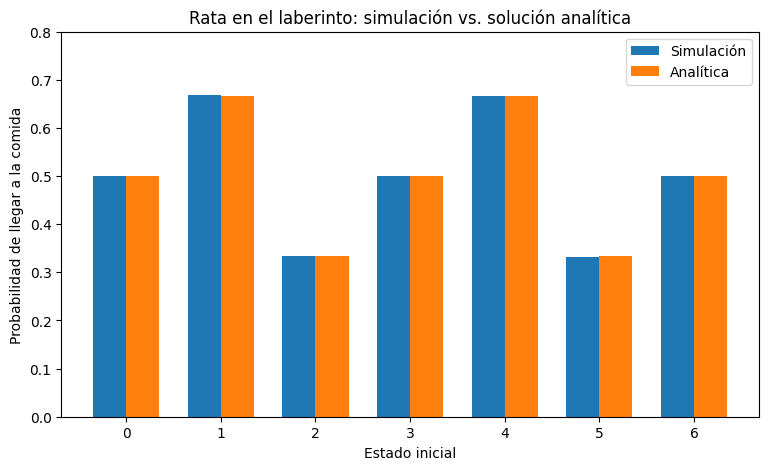

In [32]:
estados = list(range(7))
valores_simulados = [simuladas[i] for i in estados]
valores_analiticos = [analiticas[i] for i in estados]

ancho = 0.35
x = list(range(len(estados)))

plt.figure(figsize=(9, 5))
plt.bar([i - ancho/2 for i in x], valores_simulados, width=ancho, label="Simulación")
plt.bar([i + ancho/2 for i in x], valores_analiticos, width=ancho, label="Analítica")

plt.xticks(x, estados)
plt.ylim(0, 0.8)
plt.xlabel("Estado inicial")
plt.ylabel("Probabilidad de llegar a la comida")
plt.title("Rata en el laberinto: simulación vs. solución analítica")
plt.legend()
plt.show()



### Resultado del ejercicio 1

Para el estado inicial **0**, la simulación produce un valor muy cercano a:

$$
\boxed{P(\text{comida antes que descarga})=0.5}
$$

Por lo tanto, la simulación coincide con el resultado analítico.



# <font color="seagreen">2) Serpientes y escaleras</font>

El juego inicia en la casilla **1** y termina en la casilla **20**.

Las casillas especiales del tablero son:

**Escaleras**

$$
3 \rightarrow 11,\qquad 15 \rightarrow 19
$$

**Serpientes**

$$
13 \rightarrow 4,\qquad 17 \rightarrow 10
$$

Cada tirada del dado tiene seis resultados posibles, todos con probabilidad $\frac{1}{6}$.


### Paso 1. Guardar las serpientes y las escaleras

Se crean dos diccionarios con las casillas especiales.


In [33]:
escaleras = {
    3: 11,
    15: 19
}

serpientes = {
    13: 4,
    17: 10
}

print("Escaleras:", escaleras)
print("Serpientes:", serpientes)


Escaleras: {3: 11, 15: 19}
Serpientes: {13: 4, 17: 10}


### Paso 2. Definir el movimiento de una tirada

Primero se suma el resultado del dado.

Después:

1. Si se alcanza o rebasa la casilla 20, el juego termina en 20.
2. Si se cae en una escalera, se sube.
3. Si se cae en una serpiente, se baja.

Esta es la misma convención utilizada en la solución analítica para construir la cadena absorbente.


In [34]:
def mover(posicion, dado):
    nueva_posicion = posicion + dado

    # La casilla 20 es absorbente
    if nueva_posicion >= 20:
        return 20

    # Revisar escalera
    if nueva_posicion in escaleras:
        nueva_posicion = escaleras[nueva_posicion]

    # Revisar serpiente
    elif nueva_posicion in serpientes:
        nueva_posicion = serpientes[nueva_posicion]

    return nueva_posicion


### Paso 3. Comprobar algunos movimientos

Antes de simular juegos completos, verificamos que las reglas especiales estén funcionando.


In [35]:
print("Desde 1 con dado 2:", mover(1, 2), "(debe subir de 3 a 11)")
print("Desde 11 con dado 2:", mover(11, 2), "(debe bajar de 13 a 4)")
print("Desde 14 con dado 1:", mover(14, 1), "(debe subir de 15 a 19)")
print("Desde 16 con dado 1:", mover(16, 1), "(debe bajar de 17 a 10)")


Desde 1 con dado 2: 11 (debe subir de 3 a 11)
Desde 11 con dado 2: 4 (debe bajar de 13 a 4)
Desde 14 con dado 1: 19 (debe subir de 15 a 19)
Desde 16 con dado 1: 10 (debe bajar de 17 a 10)


### Paso 4. Simular un juego completo

La siguiente función lanza el dado hasta que el jugador llega al estado absorbente 20.

Además de contar las tiradas, guarda el recorrido para poder observar una simulación completa.


In [36]:
def jugar_partida():
    posicion = 1
    tiradas = 0
    recorrido = [posicion]

    while posicion != 20:
        dado = random.randint(1, 6)
        posicion = mover(posicion, dado)

        tiradas += 1
        recorrido.append(posicion)

    return tiradas, recorrido


### Paso 5. Ver una partida individual


In [37]:
random.seed(2026)

tiradas, recorrido = jugar_partida()

print("Recorrido:", recorrido)
print("Número de tiradas:", tiradas)


Recorrido: [1, 2, 5, 10, 19, 20]
Número de tiradas: 5



### Paso 6. Repetir el juego muchas veces

Se realizan **100,000 juegos independientes**.

El promedio simulado se calcula con:

$$
\overline{T} = \frac{T_1 + T_2 + \cdots + T_N}{N}
$$

donde $T_i$ es el número de tiradas utilizadas en el juego $i$.


In [38]:
random.seed(2026)

N = 100000
resultados = []

for _ in range(N):
    tiradas, recorrido = jugar_partida()
    resultados.append(tiradas)

promedio_simulado = sum(resultados) / N

print("Número de juegos simulados:", N)
print("Promedio de tiradas:", round(promedio_simulado, 5))
print("Mínimo observado:", min(resultados))
print("Máximo observado:", max(resultados))


Número de juegos simulados: 100000
Promedio de tiradas: 6.89097
Mínimo observado: 3
Máximo observado: 39



### Paso 7. Comparación con la solución analítica

Con el método de cadenas absorbentes:

$$
F=(I-Q)^{-1}, \qquad \mathbf{t}=F\mathbf{1}
$$

El tiempo esperado partiendo de la casilla **1** es aproximadamente:

$$
\boxed{t_1=6.89835}
$$

Comparamos este valor con el promedio obtenido por simulación.


In [39]:
promedio_analitico = 6.8983466512
error = abs(promedio_simulado - promedio_analitico)

print("Resultado analítico:", round(promedio_analitico, 5))
print("Resultado simulado :", round(promedio_simulado, 5))
print("Error absoluto      :", round(error, 5))


Resultado analítico: 6.89835
Resultado simulado : 6.89097
Error absoluto      : 0.00738


### Paso 8. Distribución del número de tiradas

La siguiente gráfica muestra cuántas tiradas se necesitaron en los juegos simulados.


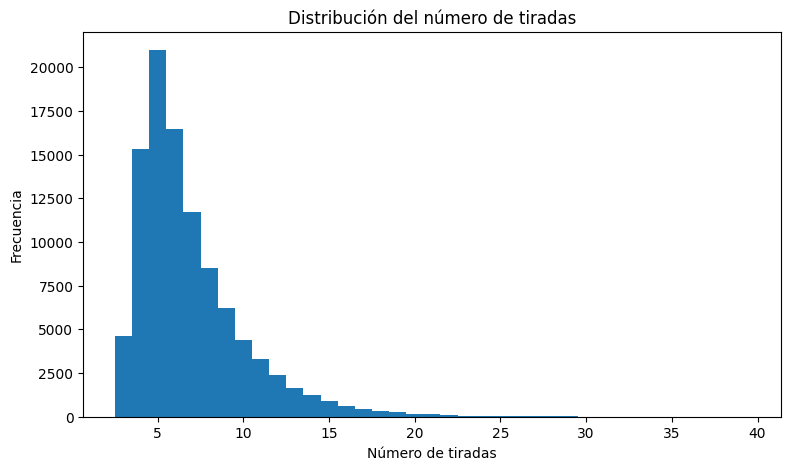

In [40]:
plt.figure(figsize=(9, 5))
plt.hist(resultados, bins=range(min(resultados), max(resultados) + 2), align="left")

plt.xlabel("Número de tiradas")
plt.ylabel("Frecuencia")
plt.title("Distribución del número de tiradas")
plt.show()



### Resultado del ejercicio 2

El promedio obtenido por simulación es muy cercano al resultado analítico:

$$
\boxed{E[T]\approx 6.89835}
$$

Por lo tanto, se necesitan aproximadamente:

$$
\boxed{6.90\text{ tiradas}}
$$

para terminar el juego.



# <font color="firebrick">Conclusiones</font>

- En el **ejercicio 1**, la simulación reproduce las probabilidades de absorción obtenidas analíticamente con $FR$.

- En el **ejercicio 2**, el promedio simulado de tiradas se aproxima al valor obtenido con $F\mathbf{1}$.

- Las pequeñas diferencias entre simulación y resultado analítico se deben al carácter aleatorio del método. Al aumentar el número de simulaciones, los resultados tienden a acercarse a los valores teóricos.
